## Mason Riffee (hmr2xq) and Asif Mohammadi (yrq8vu)

## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [ ]:
#!pip install pyarrow

   ---------------------------------------- 0.0/29.8 MB ? eta -:--:--
   --------- ------------------------------ 6.8/29.8 MB 43.6 MB/s eta 0:00:01
   ---------------------- ----------------- 17.0/29.8 MB 46.0 MB/s eta 0:00:01
   ---------------------------------- ----- 25.4/29.8 MB 43.5 MB/s eta 0:00:01
   ---------------------------------------- 29.8/29.8 MB 39.5 MB/s  0:00:00


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

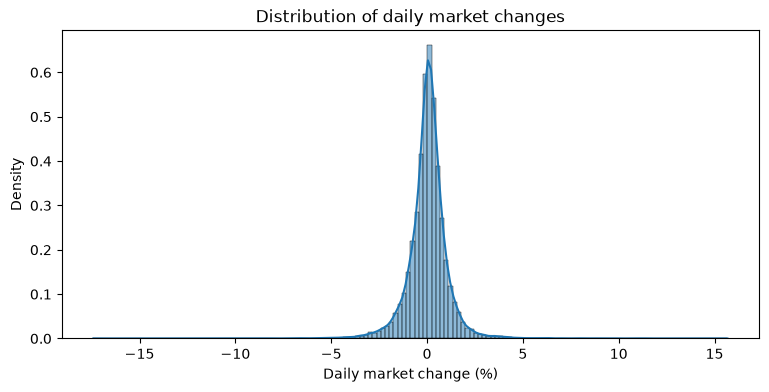

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

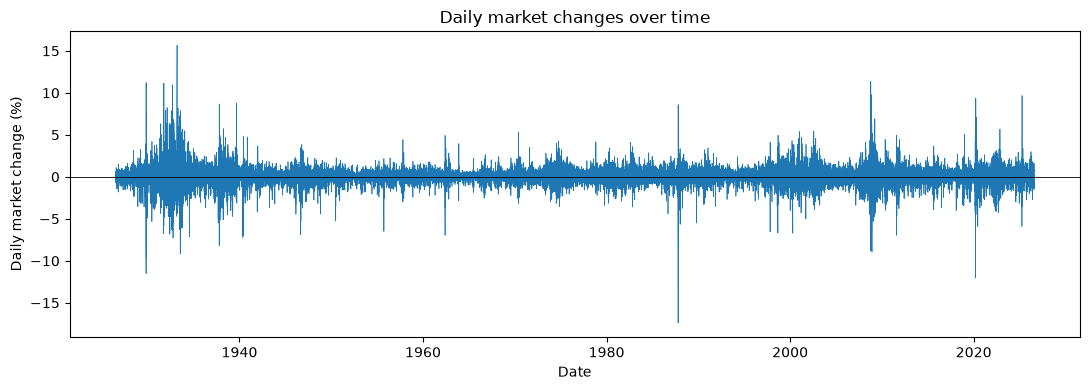

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [5]:
df.head(10)

,date,year,month,month_start,trading_day_of_month,mkt_excess_return_pct,risk_free_return_pct,market_return_pct,absolute_market_return_pct
0,1926-07-01,1926,7,1926-07-01,1,0.09,0.01,0.10,0.10
1,1926-07-02,1926,7,1926-07-01,2,0.45,0.01,0.46,0.46
2,1926-07-06,1926,7,1926-07-01,3,0.17,0.01,0.18,0.18
3,1926-07-07,1926,7,1926-07-01,4,0.09,0.01,0.10,0.10
4,1926-07-08,1926,7,1926-07-01,5,0.22,0.01,0.23,0.23
5,1926-07-09,1926,7,1926-07-01,6,-0.71,0.01,-0.70,0.70
6,1926-07-10,1926,7,1926-07-01,7,0.61,0.01,0.62,0.62
7,1926-07-12,1926,7,1926-07-01,8,0.04,0.01,0.05,0.05
8,1926-07-13,1926,7,1926-07-01,9,0.48,0.01,0.49,0.49
9,1926-07-14,1926,7,1926-07-01,10,0.04,0.01,0.05,0.05


In [6]:
df['change_type'] = np.where(df['market_return_pct'] > 0, 'Up', 'Down (and flat)')

In [7]:
y_t = df['change_type']
y_tp1 = df['change_type'].shift(-1)
df['change_type_shift1'] = y_tp1

In [8]:
df.head(3)

,date,year,month,month_start,trading_day_of_month,mkt_excess_return_pct,risk_free_return_pct,market_return_pct,absolute_market_return_pct,change_type,change_type_shift1
0,1926-07-01,1926,7,1926-07-01,1,0.09,0.01,0.10,0.10,Up,Up
1,1926-07-02,1926,7,1926-07-01,2,0.45,0.01,0.46,0.46,Up,Up
2,1926-07-06,1926,7,1926-07-01,3,0.17,0.01,0.18,0.18,Up,Up


In [9]:
#Joint:
joint_PMF = pd.crosstab(df['change_type'], df['change_type_shift1'], normalize = True)
joint_PMF

change_type_shift1,Down (and flat),Up
change_type,,
Down (and flat),0.224720,0.228142
Up,0.228142,0.318996


<Axes: xlabel='change_type_shift1', ylabel='change_type'>

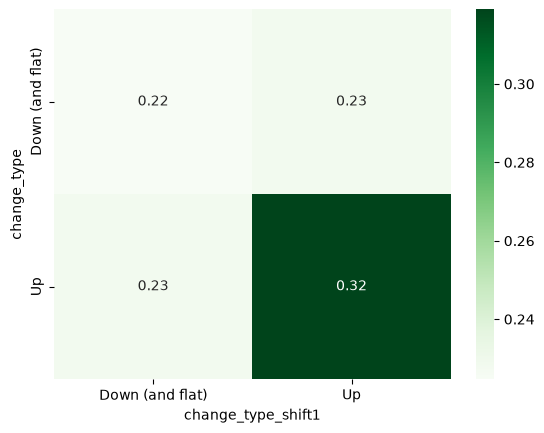

In [10]:
sns.heatmap(joint_PMF, annot=True, fmt='.2f', cmap='Greens')

In [11]:
#Marginal:
marginal_PMF = pd.crosstab(df['change_type'], df['change_type_shift1'], normalize = True, margins = True)
marginal_PMF

change_type_shift1,Down (and flat),Up,All
change_type,,,
Down (and flat),0.224720,0.228142,0.452862
Up,0.228142,0.318996,0.547138
All,0.452862,0.547138,1.000000


<Axes: xlabel='change_type_shift1', ylabel='change_type'>

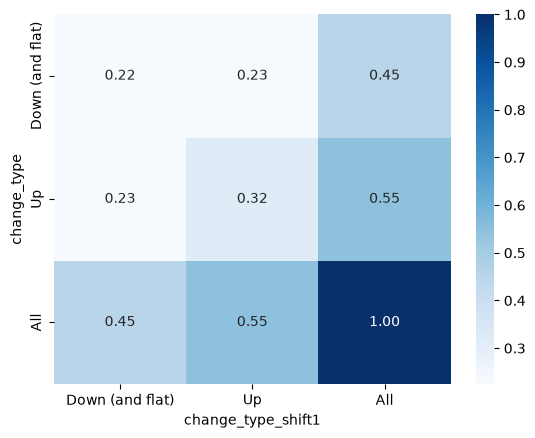

In [12]:
sns.heatmap(marginal_PMF, annot=True, fmt='.2f', cmap='Blues')

In [13]:
#Conditional:
conditional_PMF = pd.crosstab(df['change_type'], df['change_type_shift1'], normalize = 'index')
conditional_PMF

change_type_shift1,Down (and flat),Up
change_type,,
Down (and flat),0.496221,0.503779
Up,0.416974,0.583026


<Axes: xlabel='change_type_shift1', ylabel='change_type'>

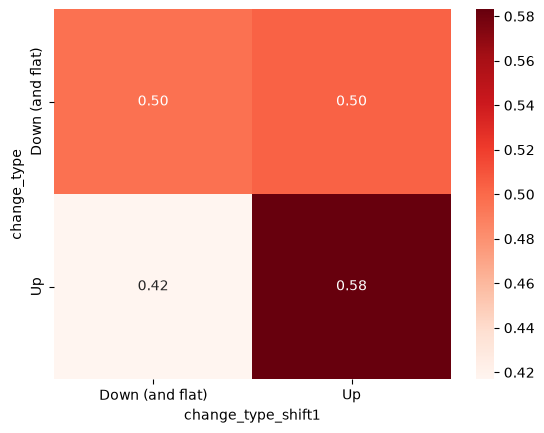

In [14]:
sns.heatmap(conditional_PMF, annot=True, fmt='.2f', cmap='Reds')

**Based on our conditional PMF (shown above in the crosstab), we calculated that an Up day has a 58% chance of being followed by another Up day, and a 42% chance of being followed by a Down or Flat day. If our current day is a Down or Flat day, it is a 50/50 chance of being an Up day or a 'Down or Flat' day the following day.**

**I would say that the current day's category is not very helpful for predicting the next day's category because these conditional probabilities are very similar and represent opposite effects.**

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [15]:
df.columns

Index(['date', 'year', 'month', 'month_start', 'trading_day_of_month',
       'mkt_excess_return_pct', 'risk_free_return_pct', 'market_return_pct',
       'absolute_market_return_pct', 'change_type', 'change_type_shift1'],
      dtype='str')

In [16]:
wdf = df[['date', 'year', 'month', 'market_return_pct']]
wdf.head(3)

,date,year,month,market_return_pct
0,1926-07-01,1926,7,0.10
1,1926-07-02,1926,7,0.46
2,1926-07-06,1926,7,0.18


In [17]:
wdf['market_return_cat'] = pd.cut(wdf['market_return_pct'], 
            bins = [-np.inf, -1, -0.1, 0.1, 1, np.inf], 
            labels = ['Large loss', 'Small loss', 'Near 0', 'Small gain', 'Large gain'])

In [18]:
wdf['market_return_cat_p1'] = wdf['market_return_cat'].shift(-1)
wdf = wdf.dropna(subset= 'market_return_cat_p1')

In [19]:
wdf['market_return_cat'].value_counts().sort_values(ascending = False)

market_return_cat
Small gain    9784
Small loss    7452
Near 0        3441
Large gain    2859
Large loss    2759
Name: count, dtype: int64

**A small gain is the most common, with 9785 occurrences in the data set. A large loss is the least common (but still not uncommon!) with 2759 occurrences.**

In [20]:
joint_PMF = pd.crosstab(wdf['market_return_cat'], wdf['market_return_cat_p1'], normalize = True)
joint_PMF

market_return_cat_p1,Large loss,Small loss,Near 0,Small gain,Large gain
market_return_cat,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382
Near 0,0.009317,0.041985,0.020955,0.049325,0.009279
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928


<Axes: xlabel='market_return_cat_p1', ylabel='market_return_cat'>

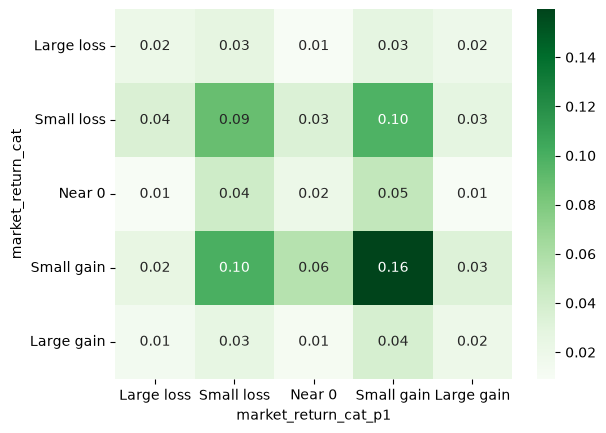

In [21]:
sns.heatmap(joint_PMF, annot=True, fmt='.2f', cmap='Greens')

In [22]:
marginal_PMF = pd.crosstab(wdf['market_return_cat'], wdf['market_return_cat_p1'], normalize = True, margins = True)
marginal_PMF

market_return_cat_p1,Large loss,Small loss,Near 0,Small gain,Large gain,All
market_return_cat,,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near 0,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


<Axes: xlabel='market_return_cat_p1', ylabel='market_return_cat'>

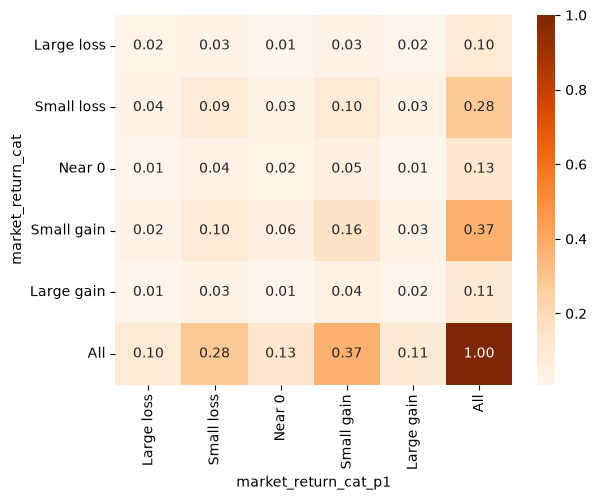

In [23]:
sns.heatmap(marginal_PMF, annot=True, fmt='.2f', cmap='Oranges')

**As we can see in the crosstab heatmaps for the joint and marginal PMF's, a small gain is the most likely shift to occur. This can be seen as 0.16 in the joint PMF heatmap, meaning that there is a 0.16 probability of two consecutive small gain days being observed; and it can be seen as 0.37 in the maringal PMF heatmap, meaning that for any given day, there is a 0.37 probability that the following day will exhibit a small gain.**

In [24]:
conditional_PMF = pd.crosstab(wdf['market_return_cat'], wdf['market_return_cat_p1'], normalize = 'index')
conditional_PMF

market_return_cat_p1,Large loss,Small loss,Near 0,Small gain,Large gain
market_return_cat,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near 0,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281


<Axes: xlabel='market_return_cat_p1', ylabel='market_return_cat'>

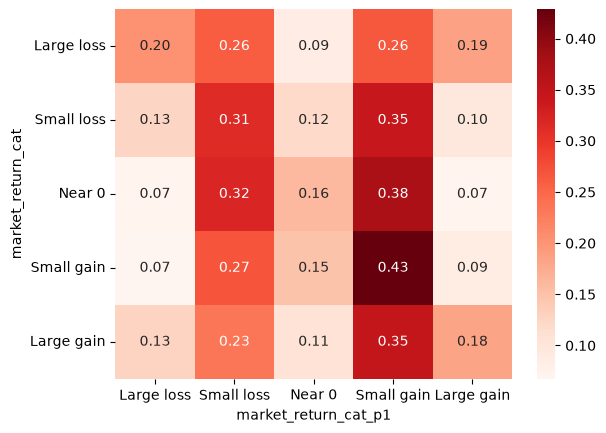

In [25]:
sns.heatmap(conditional_PMF, annot=True, fmt='.2f', cmap='Reds')

#For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?

**If today exhibited a large loss: a small gain or a small loss are most likely to occur, each with probability 0.26.**

**If today exhibited a small loss: a small gain is most likely, with probability 0.35, followed by a small loss with probability 0.31**

**If today exhibited near-zero returns: a small gain is most likely, with probability 0.38, followed by a small loss with probability 0.32**

**If today exhibited a small gain: a small gain is most likely, with probability 0.43, followed by a small loss with probability 0.27**

**If today exhibited a large gain: a small gain is most likely, with probability 0.35, followed by a small loss with probability 0.23**

**For any given state today, the state of the next day does not look like a uniform mass function. However, the next day is is not easy to predict because the likelihood of gains and losses tend to be symmetrical: for example a small gain and a small loss are both similarly likely for any given day. Large gains or losses tend to be more likely if the current day experienced a large gain or loss, but even then, a large gain is nearly as likely as a large loss.**

**Overall, the small gain tends to by slightly more likely than a small loss, but the difference is slight.**

Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. 

In [26]:
wdf['market_return_pct_p1'] = wdf['market_return_pct'].shift(-1)

In [36]:
wdf.groupby('market_return_cat', observed=False)['market_return_pct_p1'].describe()

,count,mean,std,min,25%,50%,75%,max
market_return_cat,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near 0,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2858.0,0.162904,1.384292,-12.00,-0.37,0.15,0.73,15.67


 For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this.

**(The code is above) The conditional expected return for every state is very close to zero. After a loss day, the expected return is slightly negative and after a gain day, it is slightly positive. But these numbers are too small to be useful for prediction.**

**The range of the values are wide when we have a large gain or large loss and the range becomes smaller when the gain or loss becomes smaller or near zero. So that means that big days are followed by more big days. And calmer days are followed by calm days. For example, if you made a large loss today, tomorrow ranges from (-17.41 to 11.22). However, if you are near zero today, tomorrow ranges from (-8.19 to 5.49) which is much smaller compared to the previous range.**

**In terms of volatility, large swings in the market today mean that there is a greater probability of large swings in the market tomorrow. In other words, volatility today means that tomorrow is also more likely to be volatile; whereas a calm day is less likely to be followed by a volatile day.**

**In short, today's state can be used to predict how variable the market will be tommorow, but it does not reveal much useful information about which direction the market will move.**

Below, we calculated the porportional change in standard deviation between a volatile day (numerator) and the average standard deviation of all days (denominator). It is the standard deviation of the next trading day. I got it by running df['ret_tp1'].describe(). a typical trading day moves the market about 1.077% up or down from the average day.

```
After a Large gain:
1.384 / 1.077 = 1.285 -> (1.285 − 1) * 100 = 28%
After a Large loss:
1.721/ 1.077 = 1.598 -> (1.598 − 1) * 100 = 60%
```

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [28]:
wdf['y_t'] = pd.qcut(wdf['market_return_pct'], q = 21)

In [29]:
wdf['y_tp1'] = wdf['y_t'].shift(-1)

<Axes: xlabel='y_tp1', ylabel='y_t'>

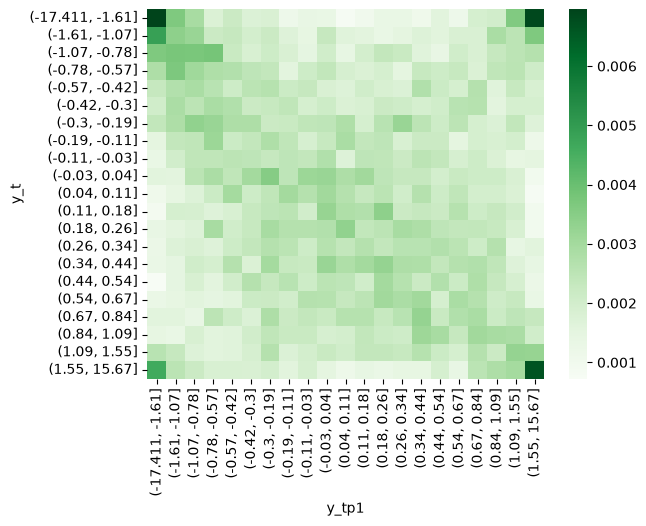

In [30]:
joint_PMF = pd.crosstab(wdf['y_t'], wdf['y_tp1'], normalize = True)
sns.heatmap(joint_PMF, annot=False, fmt='.2f', cmap='Greens')

<Axes: xlabel='y_tp1', ylabel='y_t'>

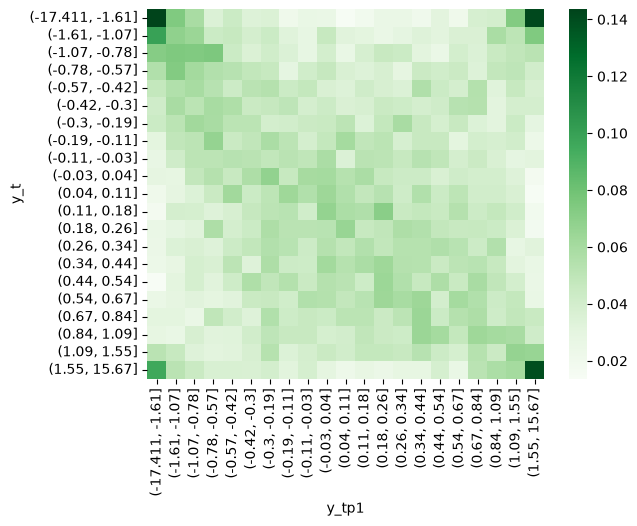

In [40]:
joint2 = joint_PMF - 1/21**2
sns.heatmap(joint2, annot=False, fmt='.2f', cmap='Greens')

**We do not see any glaring patters in the joint PMF heatmap. It looks like any given % return bin is slightly more likely to be followed by the same % return bin the next day, as opposed to being followed by a different return % bin, and this creates the faint 'X' pattern in the heatmap. However,  this is a very faint pattern and does not a large difference in probabilities: for example, the range of probabilities we are looking at are from 0% to 0.6%. So we would say that this plot does not help us predict the next day's outcome of the market.**

<Axes: xlabel='y_tp1', ylabel='y_t'>

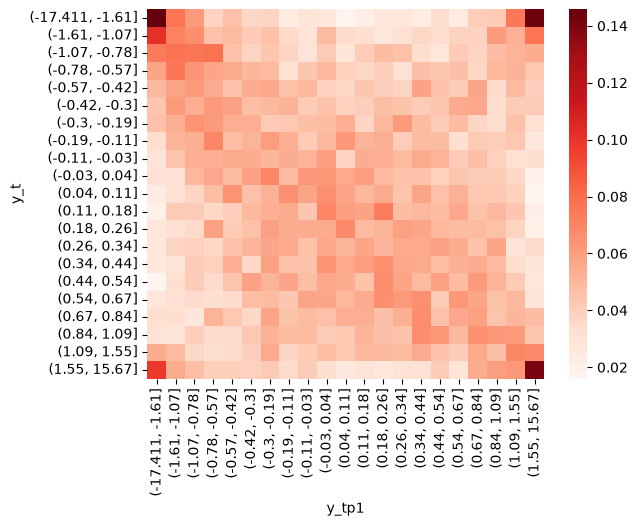

In [41]:
conditional_PMF = pd.crosstab(wdf['y_t'], wdf['y_tp1'], normalize = 'index')
sns.heatmap(conditional_PMF, annot=False, fmt='.2f', cmap='Reds')

<Axes: xlabel='y_tp1', ylabel='y_t'>

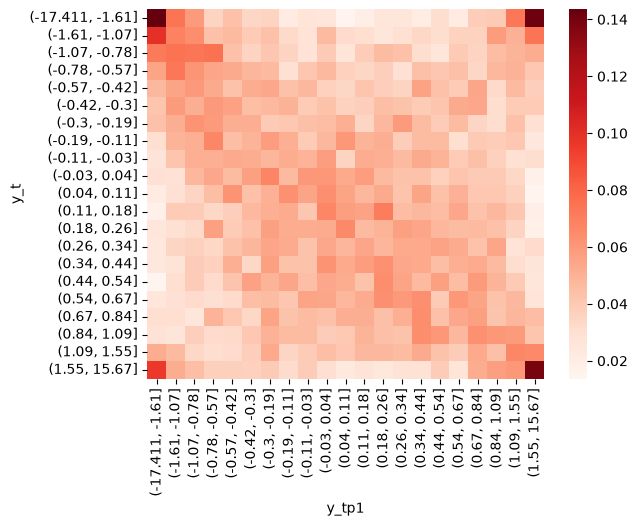

In [43]:
cond2 = conditional_PMF - 1/21**2
sns.heatmap(cond2, annot=False, fmt='.2f', cmap='Reds')

**We see the same pattern here with the conditional PMF, which is that any one % return bin does not have a large liklihood of being followed by any particular % return bin the next day. Some extreme gain/loss days have higher probability, but these days are rare and those data points are therefore less reliable for interpretation.** 

In [32]:
returns_by_bin = wdf.groupby('y_t', observed=False)['market_return_pct_p1'].describe()
returns_by_bin

,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
"(-17.411, -1.61]",1255.0,-0.013713,2.140465,-17.41,-0.9150,-0.02,0.9000,11.22
"(-1.61, -1.07]",1253.0,-0.076712,1.285882,-7.36,-0.7400,-0.02,0.6000,6.36
"(-1.07, -0.78]",1286.0,-0.097084,1.227976,-8.79,-0.7100,-0.03,0.4700,11.36
"(-0.78, -0.57]",1280.0,-0.058594,1.049607,-8.28,-0.5800,0.00,0.4925,6.16
"(-0.57, -0.42]",1230.0,-0.024211,0.989470,-6.89,-0.4675,0.02,0.4675,4.56
"(-0.42, -0.3]",1226.0,-0.022692,1.024761,-11.23,-0.4975,0.02,0.5000,6.37
"(-0.3, -0.19]",1371.0,-0.030241,0.930389,-3.94,-0.4950,0.03,0.4100,7.37
"(-0.19, -0.11]",1206.0,-0.014303,0.835663,-3.40,-0.4200,0.03,0.4100,4.76
"(-0.11, -0.03]",1198.0,0.025860,0.853220,-6.00,-0.3900,0.03,0.4400,5.49


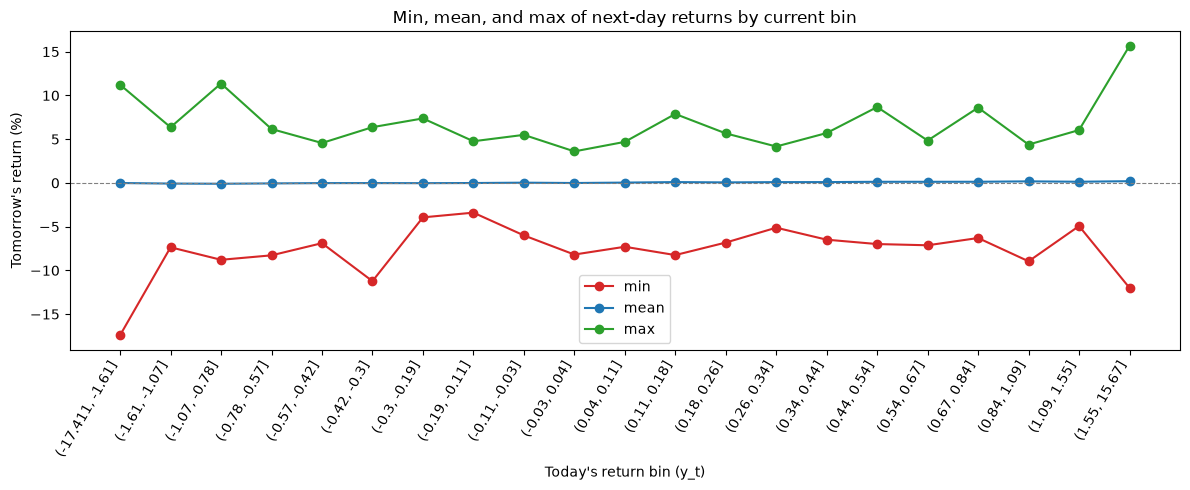

In [33]:
plot_df = returns_by_bin[['min', 'mean', 'max']]
x = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(12, 5))
for col, color in zip(['min', 'mean', 'max'], ['tab:red', 'tab:blue', 'tab:green']):
    ax.plot(x, plot_df[col], marker='o', label=col, color=color)

ax.axhline(0, color='gray', lw=0.8, ls='--')
ax.set_xticks(x)
ax.set_xticklabels([str(b) for b in plot_df.index], rotation=60, ha='right')
ax.set(xlabel="Today's return bin (y_t)",
       ylabel="Tomorrow's return (%)",
       title="Min, mean, and max of next-day returns by current bin")
ax.legend()
plt.tight_layout()
plt.show()


**Plotting the min, mean, and max expected next-day returns for the current-day's % return bin, we can see that the expected minimum return roughly mirrors the expected maximum return, and that the mean return is squashed nearly to 0. Days with extreme gains and losses tend to be followed by more volatile days, as we can see by the min and max spreading out at the extreme bins. This is even better visualized by the standard deviation plot below.**

**

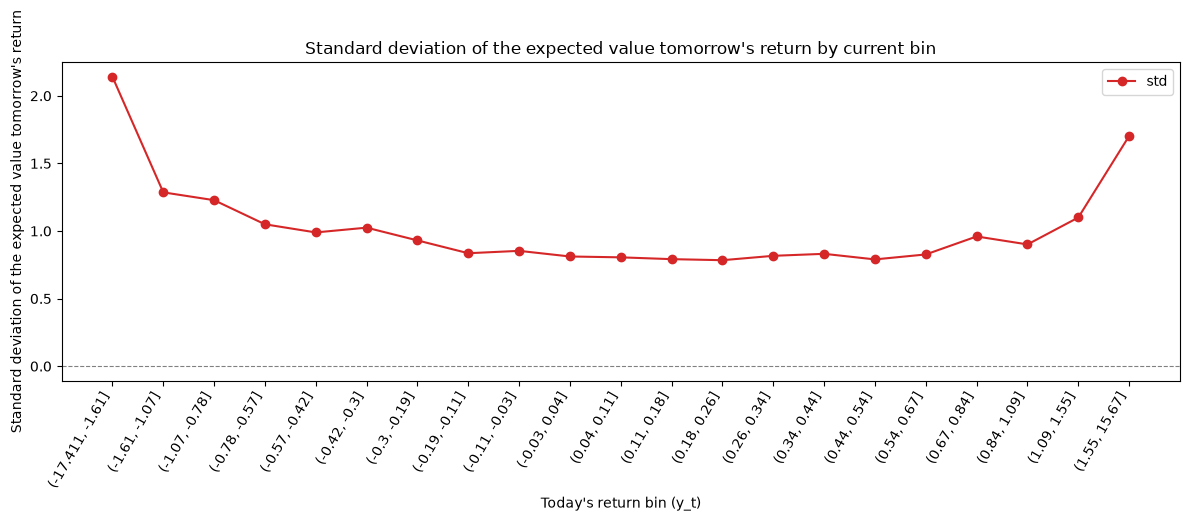

In [34]:
plot_df = returns_by_bin[['std']]
x = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(12, 5))
for col, color in zip(['std'], ['tab:red']):
    ax.plot(x, plot_df[col], marker='o', label=col, color=color)

ax.axhline(0, color='gray', lw=0.8, ls='--')
ax.set_xticks(x)
ax.set_xticklabels([str(b) for b in plot_df.index], rotation=60, ha='right')
ax.set(xlabel="Today's return bin (y_t)",
       ylabel="Standard deviation of the expected value tomorrow's return",
       title="Standard deviation of the expected value tomorrow's return by current bin")
ax.legend()
plt.tight_layout()
plt.show()

**In terms of the volatility of the market, the standard deviation plot here mirrors what we saw earlier in part 2, though with greater specificity in the bins: that is, volatile days in the stock market are more likely to be followed by another volatile day, where stable days are less likely to be followed by a volatile day. Though this does not help us predict the gains or losses in the market, it does help us to understand how the stock market moves.**

**For example, if today is has a very big loss, many investors will panic and sell their stocks on the assumption that a big loss today means another big loss is coming tomorrow. Our analysis shows instead that a big loss today does affect the liklihood of the next days return (positive or negative) very much, though it does increase the liklihood that tomorrow will also be volatile. Therefore, it is similarly likely that the market could recover tomorrow with volatile positive growth, as it could get worse with volatile depeciation.**

**As an investor, this means that you should not try to predict what the market will do tomorrow, as you are just as likely to miss a big gain tomorrow as you are to miss a big loss tomorrow if you sell your stocks. Instead, you should ride out the volatility on the premise that your stocks will grow over time. Please see what we have to say regarding this premise (of long term growth) below:**

**While it is very hard to predict what the market will do tomorrow, that does not mean that we cannot predict what the market is likely to do in the long run, such as over the course of decades. We noticed that the 5-bin marginal PMF heatmaps showed that a small gain tomorrow is slighly more likely than a small loss for any given day; over the course of time, this could create large growth in a stock asset. This also squares with what we have heard regarding responsible investing and personal finance: do not try to predict or time the market, but keep your money invested through upturns and downturns and it is most likely to grow over time.**

**Up until this point we have not used Claude, but below I asked Claude to compute a handful of Markov chains and to use our 5-bin conditional PMF to make the transition matrix for the chains. The graph is plotted below, and it clearly shows that even a small difference in marginal probabilities can lead to large changes over time, even if a reliable prediction in the short term is impossible.**

**So, we would say that it is only hard to predict the market if you're impatient! If you have the patience to wait 20 years, it is a reasonably safe bet that your investments will grow.**

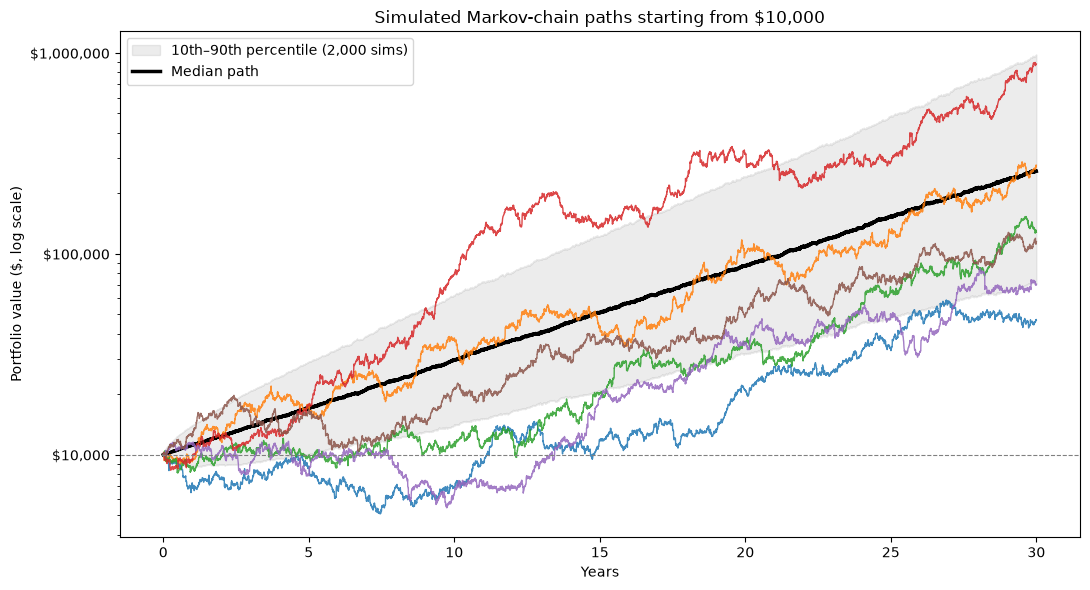

In [35]:
rng = np.random.default_rng(5030)

# Transition matrix from the 5-bin conditional PMF computed earlier
cats = wdf['market_return_cat'].cat.categories
P = conditional_PMF.reindex(index=cats, columns=cats).to_numpy()
cumP = P.cumsum(axis=1)
K = len(cats)

# Historical returns grouped by bin, so we can resample real returns from each state
s_t = wdf['market_return_cat'].cat.codes.to_numpy()
rets = wdf['market_return_pct'].to_numpy()
order = np.argsort(s_t, kind='stable')
sorted_rets = rets[order]
counts = np.bincount(s_t[s_t >= 0], minlength=K)
offsets = np.concatenate([[0], counts.cumsum()[:-1]])
marginal = counts / counts.sum()


def simulate(n_paths, n_days, start_money=10_000):
    state = rng.choice(K, size=n_paths, p=marginal)
    wealth = np.empty((n_days + 1, n_paths))
    wealth[0] = start_money
    for t in range(1, n_days + 1):
        u = rng.random(n_paths)
        state = (cumP[state] < u[:, None]).sum(axis=1)               # next state
        idx = offsets[state] + (rng.random(n_paths) * counts[state]).astype(int)
        r = sorted_rets[idx]                                          # daily log return, %
        wealth[t] = wealth[t - 1] * np.exp(r / 100)
    return wealth

n_days = 252 * 30          # 30 years of trading days
years = np.arange(n_days + 1) / 252

many = simulate(2000, n_days)   # for the typical-path summary
few = many[:, :6]               # a handful to show individually

fig, ax = plt.subplots(figsize=(11, 6))
lo, med, hi = np.percentile(many, [10, 50, 90], axis=1)
ax.fill_between(years, lo, hi, color='gray', alpha=0.15, label='10th–90th percentile (2,000 sims)')
ax.plot(years, med, color='black', lw=2.5, label='Median path')
ax.plot(years, few, lw=1, alpha=0.85)
ax.axhline(10_000, color='gray', ls='--', lw=0.8)

ax.set_yscale('log')
ax.set(xlabel='Years', ylabel='Portfolio value ($, log scale)',
       title='Simulated Markov-chain paths starting from $10,000')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'${v:,.0f}'))
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()
